#### Вспомогательные функции и импорты

In [24]:
import matplotlib.pyplot as plt
import numpy as np

def tridiag_solve(lower, main, upper, rhs):
    n = len(main)
    
    a = np.array(lower, dtype=float)   # нижняя диагональ (длина n, a[0] фиктивный)
    b = np.array(main, dtype=float)    # главная диагональ (длина n)
    c = np.array(upper, dtype=float)   # верхняя диагональ (длина n - 1)
    d = np.array(rhs, dtype=float)     # правая часть (длина n)
    
    P = np.zeros(n - 1, dtype=float) 
    Q = np.zeros(n - 1, dtype=float)  
    
    # Прямой ход
    P[0] = -c[0] / b[0]
    Q[0] = d[0] / b[0]
    
    for i in range(1, n - 1):
        denom = b[i] + a[i] * P[i - 1]
        P[i] = -c[i] / denom
        Q[i] = (d[i] - a[i] * Q[i - 1]) / denom
    
    # Обратный ход
    x = np.zeros(n, dtype=float)
    x[n - 1] = (d[n - 1] - a[n - 1] * Q[n - 2]) / (b[n - 1] + a[n - 1] * P[n - 2])
    
    for i in range(n - 2, -1, -1):
        x[i] = P[i] * x[i + 1] + Q[i]
    
    return x


def lu_decomposition(A):
    n = A.shape[0]
    U = A.astype(float).copy()
    L = np.eye(n)
    P = np.eye(n)

    for k in range(n):
        max_row = k
        max_val = abs(U[k, k])
        for i in range(k + 1, n):
            if abs(U[i, k]) > max_val:
                max_val = abs(U[i, k])
                max_row = i

        if max_row != k:
            U[[k, max_row]] = U[[max_row, k]]
            P[[k, max_row]] = P[[max_row, k]]
            if k > 0:
                L[[k, max_row], :k] = L[[max_row, k], :k]

        if U[k, k] == 0:
            raise ValueError(
                "Матрица вырожденная (нулевой элемент на диагонали)"
            )

        for i in range(k + 1, n):
            L[i, k] = U[i, k] / U[k, k]
            for j in range(k, n):
                U[i, j] -= L[i, k] * U[k, j]

    return L, U, P


def lu_solve(L, U, P, b):
    n = len(b)
    b_new = P @ b.astype(float)

    y = np.zeros(n, dtype=float)
    for i in range(n):
        y[i] = b_new[i] - np.dot(L[i, :i], y[:i])

    x = np.zeros(n, dtype=float)
    for i in range(n - 1, -1, -1):
        x[i] = (y[i] - np.dot(U[i, i + 1 :], x[i + 1 :])) / U[i, i]

    return x
    

---
# **3.1. Интерполяционный многочлен Лагранжа и Ньютона**

In [25]:
def lagrange_basis_str(x_nodes, i):
    xi = x_nodes[i]
    num_parts = []
    denom = 1.0
    for j, xj in enumerate(x_nodes):
        if j != i:
            sign = "+" if xj < 0 else "-"
            val = abs(xj)
            num_parts.append(f"(x {sign} {val:.4g})")
            denom *= xi - xj

    num_str = "".join(num_parts)
    return num_str, denom


def lagrange_polynomial_str(x_nodes, y_nodes):
    terms = []
    for i in range(len(x_nodes)):
        num_str, denom = lagrange_basis_str(x_nodes, i)
        coeff = y_nodes[i] / denom
        sign = "+ " if coeff >= 0 and i > 0 else ("- " if coeff < 0 else "")
        val = abs(coeff) if i > 0 else coeff
        terms.append(f"{sign}{val:.6f}*{num_str}")
    return " ".join(terms)


def lagrange_interpolate(x_nodes, y_nodes, x):
    x = np.asarray(x, dtype=float)
    n = len(x_nodes)
    total = np.zeros_like(x, dtype=float)

    for i in range(n):
        basis = np.ones_like(x, dtype=float)
        for j in range(n):
            if i != j:
                basis *= (x - x_nodes[j]) / (x_nodes[i] - x_nodes[j])
        total += y_nodes[i] * basis

    return total


def divided_differences_table(x_nodes, y_nodes):
    n = len(x_nodes)
    table = np.zeros((n, n), dtype=float)
    table[:, 0] = y_nodes

    for j in range(1, n):
        for i in range(n - j):
            table[i, j] = (table[i + 1, j - 1] - table[i, j - 1]) / (
                x_nodes[i + j] - x_nodes[i]
            )

    return table


def newton_polynomial_str(x_nodes, coeffs):
    terms = [f"{coeffs[0]:.6f}"]
    for k in range(1, len(coeffs)):
        coeff = coeffs[k]
        sign = "+ " if coeff >= 0 else "- "
        factors = []
        for j in range(k):
            xj = x_nodes[j]
            s = "+" if xj < 0 else "-"
            factors.append(f"(x {s} {abs(xj):.4g})")
        factors_str = "".join(factors)
        terms.append(f"{sign}{abs(coeff):.6f}*{factors_str}")
    return " ".join(terms)


def newton_interpolate(x_nodes, coeffs, x):
    x = np.asarray(x, dtype=float)
    n = len(coeffs)
    result = np.full_like(x, coeffs[-1], dtype=float)

    for i in range(n - 2, -1, -1):
        result = result * (x - x_nodes[i]) + coeffs[i]

    return result

In [26]:
def solve_interpolation_task(func, x_nodes, x_star):
    x_nodes = np.array(x_nodes, dtype=float)
    y_nodes = np.array([func(x) for x in x_nodes], dtype=float)
    n = len(x_nodes)

    print("=" * 70)
    print("1. ИСХОДНЫЕ УЗЛЫ И ЗНАЧЕНИЯ ФУНКЦИИ:")
    print(f"{'i':^4} | {'x_i':^12} | {'y_i = f(x_i)':^16}")
    print("-" * 38)
    for i in range(n):
        print(f"{i:^4} | {x_nodes[i]:^12.4f} | {y_nodes[i]:^16.6f}")

    lagrange_str = lagrange_polynomial_str(x_nodes, y_nodes)
    print("\n" + "=" * 70)
    print("2. ИНТЕРПОЛЯЦИОННЫЙ МНОГОЧЛЕН ЛАГРАНЖА:")
    print(f"L_{n-1}(x) = {lagrange_str}")

    diff_table = divided_differences_table(x_nodes, y_nodes)
    print("\n" + "=" * 70)
    print("3. ТАБЛИЦА РАЗДЕЛЁННЫХ РАЗНОСТЕЙ:")
    headers = [f"Порядок {k}" for k in range(n)]
    header_str = (
        f"{'i':^4} | {'x_i':^10} | "
        + " | ".join(f"{h:^14}" for h in headers)
    )
    print(header_str)
    print("-" * len(header_str))
    for i in range(n):
        row_vals = [
            f"{diff_table[i, j]:^14.6f}" if j < n - i else f"{'-':^14}"
            for j in range(n)
        ]
        print(
            f"{i:^4} | {x_nodes[i]:^10.4f} | " + " | ".join(row_vals)
        )

    newton_coeffs = diff_table[0, :]
    newton_str = newton_polynomial_str(x_nodes, newton_coeffs)
    print("\n" + "=" * 70)
    print("4. ИНТЕРПОЛЯЦИОННЫЙ МНОГОЧЛЕН НЬЮТОНА:")
    print(f"P_{n-1}(x) = {newton_str}")

    val_lagrange = float(lagrange_interpolate(x_nodes, y_nodes, x_star))
    print("\n" + "=" * 70)
    print(f"5. ЗНАЧЕНИЕ МНОГОЧЛЕНА ЛАГРАНЖА В ТОЧКЕ x* = {x_star}:")
    print(f"L_{n-1}({x_star}) = {val_lagrange:.8f}")

    val_newton = float(newton_interpolate(x_nodes, newton_coeffs, x_star))
    print("\n" + "=" * 70)
    print(f"6. ЗНАЧЕНИЕ МНОГОЧЛЕНА НЬЮТОНА В ТОЧКЕ x* = {x_star}:")
    print(f"P_{n-1}({x_star}) = {val_newton:.8f}")

    exact_val = float(func(x_star))
    print("\n" + "=" * 70)
    print(f"7. ТОЧНОЕ ЗНАЧЕНИЕ ФУНКЦИИ В ТОЧКЕ x* = {x_star}:")
    print(f"f({x_star}) = {exact_val:.8f}")

    err_lagrange = abs(exact_val - val_lagrange)
    err_newton = abs(exact_val - val_newton)
    print("\n" + "=" * 70)
    print("8. АБСОЛЮТНАЯ ПОГРЕШНОСТЬ ИНТЕРПОЛЯЦИИ:")
    print(
        f"|f(x*) - L(x*)| = {err_lagrange:.8e} (относительно Лагранжа)"
    )
    print(
        f"|f(x*) - P(x*)| = {err_newton:.8e} (относительно Ньютона)"
    )

    diff_ln = abs(val_lagrange - val_newton)
    print("\n" + "=" * 70)
    print("9. РАЗНОСТЬ МЕЖДУ РЕЗУЛЬТАТАМИ МЕТОДОВ ЛАГРАНЖА И НЬЮТОНА:")
    print(f"|L(x*) - P(x*)| = {diff_ln:.8e}")
    print("=" * 70)

    x_min = min(np.min(x_nodes), x_star)
    x_max = max(np.max(x_nodes), x_star)
    margin = 0.1 * (x_max - x_min)
    x_plot = np.linspace(x_min - margin, x_max + margin, 400)

    y_exact_plot = np.array([func(x) for x in x_plot])
    y_lagrange_plot = lagrange_interpolate(x_nodes, y_nodes, x_plot)
    y_newton_plot = newton_interpolate(x_nodes, newton_coeffs, x_plot)

    plt.figure(figsize=(10, 6))
    plt.plot(
        x_plot,
        y_exact_plot,
        label=r"Исходная функция $f(x)$",
        color="black",
        linewidth=2,
    )
    plt.plot(
        x_plot,
        y_lagrange_plot,
        "--",
        label=r"Полином Лагранжа $L(x)$",
        color="royalblue",
        linewidth=1.8,
    )
    plt.plot(
        x_plot,
        y_newton_plot,
        ":",
        label=r"Полином Ньютона $P(x)$",
        color="crimson",
        linewidth=2.2,
    )

    plt.scatter(
        x_nodes,
        y_nodes,
        color="darkblue",
        s=60,
        zorder=5,
        label=r"Узлы интерполяции $(x_i, y_i)$",
    )

    plt.scatter(
        [x_star],
        [val_lagrange],
        color="gold",
        edgecolors="black",
        s=120,
        zorder=6,
        label=f"Точка $x^* = {x_star}$",
    )

    plt.title(
        "Интерполяция многочленами Лагранжа и Ньютона", fontsize=13
    )
    plt.xlabel("x", fontsize=11)
    plt.ylabel("y", fontsize=11)
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.legend(loc="best", fontsize=10)
    plt.tight_layout()
    plt.show()

1. ИСХОДНЫЕ УЗЛЫ И ЗНАЧЕНИЯ ФУНКЦИИ:
 i   |     x_i      |   y_i = f(x_i)  
--------------------------------------
 0   |   -0.4000    |     1.982313    
 1   |   -0.1000    |     1.670964    
 2   |    0.2000    |     1.369438    
 3   |    0.5000    |     1.047198    

2. ИНТЕРПОЛЯЦИОННЫЙ МНОГОЧЛЕН ЛАГРАНЖА:
L_3(x) = - -12.236501*(x + 0.1)(x - 0.2)(x - 0.5) + 30.943773*(x + 0.4)(x - 0.2)(x - 0.5) - 25.359970*(x + 0.4)(x + 0.1)(x - 0.5) + 6.464182*(x + 0.4)(x + 0.1)(x - 0.2)

3. ТАБЛИЦА РАЗДЕЛЁННЫХ РАЗНОСТЕЙ:
 i   |    x_i     |   Порядок 0    |   Порядок 1    |   Порядок 2    |   Порядок 3   
-------------------------------------------------------------------------------------
 0   |  -0.4000   |    1.982313    |   -1.037831    |    0.054578    |   -0.188516   
 1   |  -0.1000   |    1.670964    |   -1.005084    |   -0.115086    |       -       
 2   |   0.2000   |    1.369438    |   -1.074136    |       -        |       -       
 3   |   0.5000   |    1.047198    |       -        | 

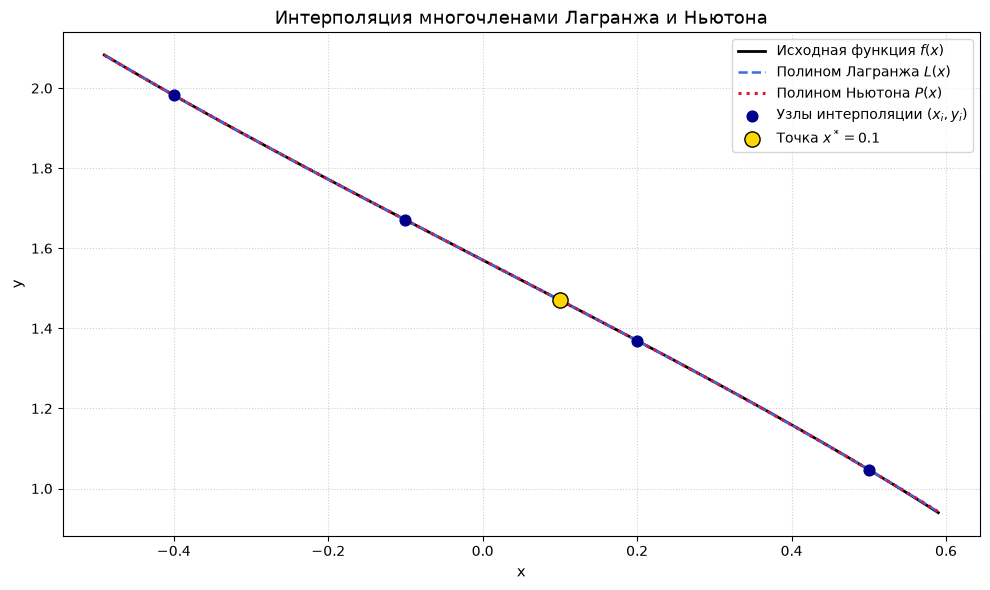

In [27]:
func = np.arccos  
x_nodes_var9_a = [-0.4, -0.1, 0.2, 0.5]
x_star_var9 = 0.1

solve_interpolation_task(func, x_nodes_var9_a, x_star_var9)

---
# **3.2. Кубический сплайн**

In [28]:
def build_cubic_spline(x_nodes, f_nodes):
    x_nodes = np.array(x_nodes, dtype=float)
    f_nodes = np.array(f_nodes, dtype=float)
    N = len(x_nodes)
    n = N - 1

    h = np.zeros(n + 1)
    for i in range(1, n + 1):
        h[i] = x_nodes[i] - x_nodes[i - 1]

    a = np.zeros(n + 1)
    for i in range(1, n + 1):
        a[i] = f_nodes[i - 1]

    m = n - 1
    lower = np.zeros(m)
    main = np.zeros(m)
    upper = np.zeros(m - 1)
    rhs = np.zeros(m)

    for idx, i in enumerate(range(2, n + 1)):
        main[idx] = 2.0 * (h[i - 1] + h[i])
        rhs[idx] = 3.0 * ((f_nodes[i] - f_nodes[i - 1]) / h[i] - 
                          (f_nodes[i - 1] - f_nodes[i - 2]) / h[i - 1])
        if idx > 0:
            lower[idx] = h[i - 1]
        if idx < m - 1:
            upper[idx] = h[i]

    c_inner = tridiag_solve(lower, main, upper, rhs)

    c = np.zeros(n + 2)
    c[1] = 0.0
    c[2:n + 1] = c_inner
    c[n + 1] = 0.0

    d = np.zeros(n + 1)
    b = np.zeros(n + 1)

    for i in range(1, n):
        d[i] = (c[i + 1] - c[i]) / (3.0 * h[i])
        b[i] = (f_nodes[i] - f_nodes[i - 1]) / h[i] - (h[i] / 3.0) * (c[i + 1] + 2.0 * c[i])

    d[n] = -c[n] / (3.0 * h[n])
    b[n] = (f_nodes[n] - f_nodes[n - 1]) / h[n] - (2.0 / 3.0) * h[n] * c[n]

    return a, b, c[:n + 1], d, h


def eval_spline(x, x_nodes, a, b, c, d):
    n = len(x_nodes) - 1

    if x <= x_nodes[0]:
        interval = 1
    elif x >= x_nodes[-1]:
        interval = n
    else:
        interval = 1
        for i in range(1, n + 1):
            if x_nodes[i - 1] <= x <= x_nodes[i]:
                interval = i
                break

    dx = x - x_nodes[interval - 1]
    val = (a[interval] + 
           b[interval] * dx + 
           c[interval] * (dx ** 2) + 
           d[interval] * (dx ** 3))
    return val, interval


def solve_spline_task(x_nodes, f_nodes, x_star):
    x_nodes = np.array(x_nodes, dtype=float)
    f_nodes = np.array(f_nodes, dtype=float)
    n = len(x_nodes) - 1

    a, b, c, d, h = build_cubic_spline(x_nodes, f_nodes)

    print("=" * 80)
    print("1. ИСХОДНЫЕ УЗЛЫ И ЗНАЧЕНИЯ ФУНКЦИИ:")
    print(f"{'i':^4} | {'x_i':^12} | {'f_i = y_i':^16}")
    print("-" * 38)
    for i in range(len(x_nodes)):
        print(f"{i:^4} | {x_nodes[i]:^12.4f} | {f_nodes[i]:^16.6f}")

    print("\n" + "=" * 80)
    print("2. КОЭФФИЦИЕНТЫ ДЛЯ КАЖДОГО УЧАСТКА СПЛАЙНА:")
    print(f"{'i':^4} | {'a_i':^14} | {'b_i':^14} | {'c_i':^14} | {'d_i':^14}")
    print("-" * 66)
    for i in range(1, n + 1):
        print(f"{i:^4} | {a[i]:^14.6f} | {b[i]:^14.6f} | {c[i]:^14.6f} | {d[i]:^14.6f}")

    print("\n" + "=" * 80)
    print("3. ИНТЕРВАЛЫ И АНАЛИТИЧЕСКИЙ ВИД МНОГОЧЛЕНОВ:")
    for i in range(1, n + 1):
        x_left = x_nodes[i - 1]
        x_right = x_nodes[i]
        sign_x = "+" if x_left < 0 else "-"
        abs_x = abs(x_left)
        print(f"Интервал {i}: x in [{x_left:.4f}; {x_right:.4f}]")
        print(f"  S_{i}(x) = {a[i]:.6f} + ({b[i]:.6f})*(x {sign_x} {abs_x:.4g}) + "
              f"({c[i]:.6f})*(x {sign_x} {abs_x:.4g})^2 + ({d[i]:.6f})*(x {sign_x} {abs_x:.4g})^3\n")

    val_star, star_interval = eval_spline(x_star, x_nodes, a, b, c, d)
    print("=" * 80)
    print(f"4. ЗНАЧЕНИЕ СПЛАЙНА В ТОЧКЕ x* = {x_star}:")
    print(f"   S({x_star}) = {val_star:.8f}")

    print("\n" + "=" * 80)
    print(f"5. НОМЕР ИНТЕРВАЛА, СОДЕРЖАЩЕГО x* = {x_star}:")
    print(f"   Интервал № {star_interval}  (отрезок [{x_nodes[star_interval - 1]:.4f}; {x_nodes[star_interval]:.4f}])")

    print("\n" + "=" * 80)
    print("6. ПРОВЕРКА ПРОХОЖДЕНИЯ СПЛАЙНА ЧЕРЕЗ ИСХОДНЫЕ УЗЛЫ:")
    print(f"{'Узел':^6} | {'x':^10} | {'Точное f_i':^14} | {'Значение S(x)':^14}")
    print("-" * 52)
    for i in range(len(x_nodes)):
        val_node, _ = eval_spline(x_nodes[i], x_nodes, a, b, c, d)
        err = abs(val_node - f_nodes[i])
        print(f"{i:^6} | {x_nodes[i]:^10.4f} | {f_nodes[i]:^14.6f} | {val_node:^14.6f}")

    d2_left = 2.0 * c[1]
    d2_right = 2.0 * c[n] + 6.0 * d[n] * h[n]

    print("\n" + "=" * 80)
    print("7. ВТОРЫЕ ПРОИЗВОДНЫЕ НА КОНЦАХ ИНТЕРВАЛА (ГРАНИЧНЫЕ УСЛОВИЯ):")
    print(f"   Левый конец  (x = x_0 = {x_nodes[0]:.4f}): S''({x_nodes[0]:.4f}) = {d2_left:.8f}")
    print(f"   Правый конец (x = x_n = {x_nodes[-1]:.4f}): S''({x_nodes[-1]:.4f}) = {d2_right:.8f}")
    print("=" * 80)

    plt.figure(figsize=(10, 6))
    colors = ['royalblue', 'forestgreen', 'darkorange', 'purple', 'teal']
    for i in range(1, n + 1):
        xs = np.linspace(x_nodes[i - 1], x_nodes[i], 100)
        dx = xs - x_nodes[i - 1]
        ys = a[i] + b[i] * dx + c[i] * (dx ** 2) + d[i] * (dx ** 3)
        plt.plot(xs, ys, label=f'Участок {i} $[x_{{{i-1}}}, x_{{{i}}}]$', 
                 color=colors[(i - 1) % len(colors)], linewidth=2)

    plt.scatter(x_nodes, f_nodes, color='red', s=60, zorder=5, label='Исходные узлы $(x_i, f_i)$')
    plt.scatter([x_star], [val_star], color='gold', edgecolors='black', 
                s=120, zorder=6, label=f'Точка $(x^*, S(x^*)) = ({x_star}, {val_star:.4f})$')

    plt.title('Интерполяция кубическим сплайном', fontsize=13)
    plt.xlabel('x', fontsize=11)
    plt.ylabel('y', fontsize=11)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend(loc='best', fontsize=10)
    plt.tight_layout()
    plt.show()

1. ИСХОДНЫЕ УЗЛЫ И ЗНАЧЕНИЯ ФУНКЦИИ:
 i   |     x_i      |    f_i = y_i    
--------------------------------------
 0   |   -0.4000    |     1.982300    
 1   |   -0.1000    |     1.671000    
 2   |    0.2000    |     1.369400    
 3   |    0.5000    |     1.047200    
 4   |    0.8000    |     0.643500    

2. КОЭФФИЦИЕНТЫ ДЛЯ КАЖДОГО УЧАСТКА СПЛАЙНА:
 i   |      a_i       |      b_i       |      c_i       |      d_i      
------------------------------------------------------------------
 1   |    1.982300    |   -1.046381    |    0.000000    |    0.096825   
 2   |    1.671000    |   -1.020238    |    0.087143    |   -0.124868   
 3   |    1.369400    |   -1.001667    |   -0.025238    |   -0.719577   
 4   |    1.047200    |   -1.211095    |   -0.672857    |    0.747619   

3. ИНТЕРВАЛЫ И АНАЛИТИЧЕСКИЙ ВИД МНОГОЧЛЕНОВ:
Интервал 1: x in [-0.4000; -0.1000]
  S_1(x) = 1.982300 + (-1.046381)*(x + 0.4) + (0.000000)*(x + 0.4)^2 + (0.096825)*(x + 0.4)^3

Интервал 2: x in [-0.1000; 0.2000]

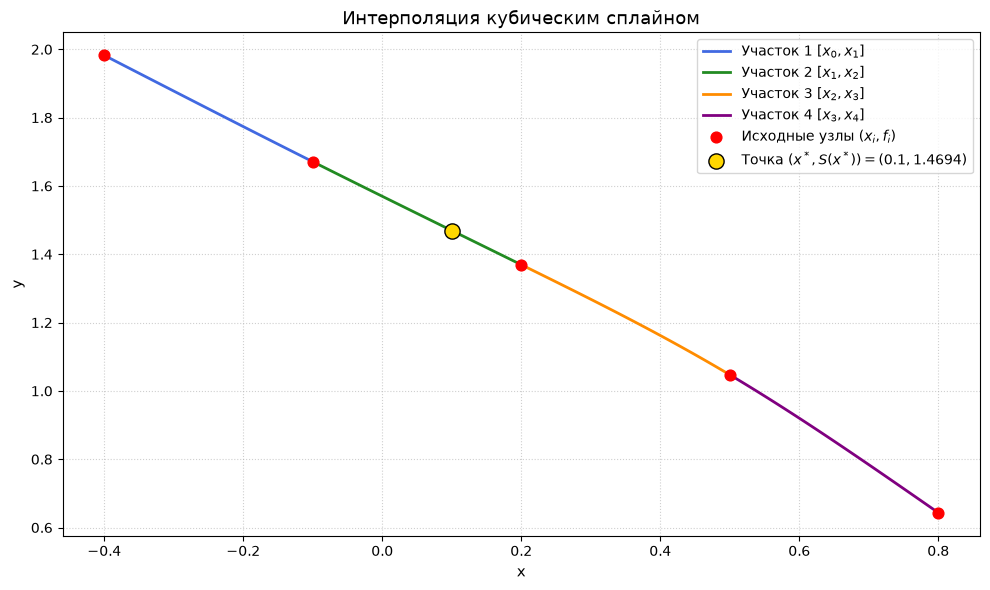

In [29]:
x_nodes_var9 = [-0.4, -0.1, 0.2, 0.5, 0.8]
f_nodes_var9 = [1.9823, 1.6710, 1.3694, 1.0472, 0.64350]
x_star_var9 = 0.1

solve_spline_task(x_nodes_var9, f_nodes_var9, x_star_var9)


---
# **3.3. Метод наименьших квадратов**

In [37]:
def solve_lsq_polynomial(x_nodes, y_nodes, degree):
    m = degree + 1
    A = np.zeros((m, m), dtype=float)
    b = np.zeros(m, dtype=float)

    for k in range(m):
        b[k] = np.sum(y_nodes * (x_nodes**k))
        for i in range(m):
            A[k, i] = np.sum(x_nodes ** (k + i))

    L, U, P = lu_decomposition(A)
    coeffs = lu_solve(L, U, P, b)
    return coeffs


def poly_eval(coeffs, x):
    res = np.zeros_like(x, dtype=float)
    for c in reversed(coeffs):
        res = res * x + c
    return res


def poly_to_str(coeffs, name="P"):
    terms = []
    for power, c in enumerate(coeffs):
        if power == 0:
            terms.append(f"{c:.6f}")
        elif power == 1:
            sign = "+ " if c >= 0 else "- "
            terms.append(f"{sign}{abs(c):.6f}*x")
        else:
            sign = "+ " if c >= 0 else "- "
            terms.append(f"{sign}{abs(c):.6f}*x^{power}")
    return f"{name}(x) = " + " ".join(terms)


def calc_errors(x_nodes, y_nodes, coeffs):
    y_pred = poly_eval(coeffs, x_nodes)
    residuals = y_pred - y_nodes
    phi = np.sum(residuals**2) 
    mse = np.mean(residuals**2)  
    return phi, mse


def solve_lsq_task(x_nodes, y_nodes):
    x_nodes = np.array(x_nodes, dtype=float)
    y_nodes = np.array(y_nodes, dtype=float)

    c1 = solve_lsq_polynomial(x_nodes, y_nodes, degree=1)
    c2 = solve_lsq_polynomial(x_nodes, y_nodes, degree=2)
    c3 = solve_lsq_polynomial(x_nodes, y_nodes, degree=3)

    phi1, mse1 = calc_errors(x_nodes, y_nodes, c1)
    phi2, mse2 = calc_errors(x_nodes, y_nodes, c2)
    phi3, mse3 = calc_errors(x_nodes, y_nodes, c3)


    print("=" * 80)
    print("1. КОЭФФИЦИЕНТЫ МНОГОЧЛЕНА 1-Й СТЕПЕНИ P_1(x):")
    for i, a in enumerate(c1):
        print(f"   a_{i} = {a:.8f}")

    print("\n" + "=" * 80)
    print("2. КОЭФФИЦИЕНТЫ МНОГОЧЛЕНА 2-Й СТЕПЕНИ P_2(x):")
    for i, a in enumerate(c2):
        print(f"   a_{i} = {a:.8f}")

    print("\n" + "=" * 80)
    print("3. КОЭФФИЦИЕНТЫ МНОГОЧЛЕНА 3-Й СТЕПЕНИ P_3(x):")
    for i, a in enumerate(c3):
        print(f"   a_{i} = {a:.8f}")

    print("\n" + "=" * 80)
    print("4. МНОГОЧЛЕНЫ В ЯВНОМ АНАЛИТИЧЕСКОМ ВИДЕ:")
    print("   " + poly_to_str(c1, "P_1"))
    print("   " + poly_to_str(c2, "P_2"))
    print("   " + poly_to_str(c3, "P_3"))

    print("\n" + "=" * 80)
    print("5. ЗНАЧЕНИЯ ОШИБОК АППРОКСИМАЦИИ:")
    print(f"   Многочлен 1-й степени:  Ф_1 = {phi1:.8f}  |  MSE_1 = {mse1:.8e}")
    print(f"   Многочлен 2-й степени:  Ф_2 = {phi2:.8f}  |  MSE_2 = {mse2:.8e}")
    print(f"   Многочлен 3-й степени:  Ф_3 = {phi3:.8f}  |  MSE_3 = {mse3:.8e}")

    print("\n" + "=" * 80)
    print("6. СРАВНЕНИЕ ПОЛУЧЕННЫХ ОШИБОК И ВЫВОД:")
    mses = [mse1, mse2, mse3]
    best_deg = int(np.argmin(mses)) + 1
    print(f"   Соотношение ошибок: MSE_3 < MSE_2 < MSE_1")
    print(f"   ({mse3:.6e} < {mse2:.6e} < {mse1:.6e})")
    print(
        f"   Наилучшее приближение табличных данных обеспечивает многочлен P_{best_deg}(x)"
    )
    print(
        f"   (степень {best_deg}), так как он минимизирует квадратичное отклонение и MSE."
    )
    print("=" * 80)

    x_min, x_max = np.min(x_nodes), np.max(x_nodes)
    margin = 0.05 * (x_max - x_min)
    x_dense = np.linspace(x_min - margin, x_max + margin, 300)

    plt.figure(figsize=(10, 6))

    plt.scatter(
        x_nodes,
        y_nodes,
        color="red",
        s=70,
        zorder=5,
        label=r"Исходные точки $(x_j, y_j)$",
    )
    plt.plot(
        x_dense,
        poly_eval(c1, x_dense),
        "--",
        color="royalblue",
        linewidth=2,
        label=f"$P_1(x)$ (MSE = {mse1:.2e})",
    )
    plt.plot(
        x_dense,
        poly_eval(c2, x_dense),
        "-.",
        color="forestgreen",
        linewidth=2,
        label=f"$P_2(x)$ (MSE = {mse2:.2e})",
    )
    plt.plot(
        x_dense,
        poly_eval(c3, x_dense),
        "-",
        color="crimson",
        linewidth=2.2,
        label=f"$P_3(x)$ (MSE = {mse3:.2e})",
    )

    plt.title(
        "Аппроксимация функции методом наименьших квадратов", fontsize=13
    )
    plt.xlabel("x", fontsize=11)
    plt.ylabel("y", fontsize=11)
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.legend(loc="best", fontsize=10)
    plt.tight_layout()
    plt.show()

1. КОЭФФИЦИЕНТЫ МНОГОЧЛЕНА 1-Й СТЕПЕНИ P_1(x):
   a_0 = 1.56526857
   a_1 = -1.10670476

2. КОЭФФИЦИЕНТЫ МНОГОЧЛЕНА 2-Й СТЕПЕНИ P_2(x):
   a_0 = 1.57778365
   a_1 = -1.10189127
   a_2 = -0.04813492

3. КОЭФФИЦИЕНТЫ МНОГОЧЛЕНА 3-Й СТЕПЕНИ P_3(x):
   a_0 = 1.57188254
   a_1 = -0.98517460
   a_2 = -0.00896825
   a_3 = -0.26111111

4. МНОГОЧЛЕНЫ В ЯВНОМ АНАЛИТИЧЕСКОМ ВИДЕ:
   P_1(x) = 1.565269 - 1.106705*x
   P_2(x) = 1.577784 - 1.101891*x - 0.048135*x^2
   P_3(x) = 1.571883 - 0.985175*x - 0.008968*x^2 - 0.261111*x^3

5. ЗНАЧЕНИЯ ОШИБОК АППРОКСИМАЦИИ:
   Многочлен 1-й степени:  Ф_1 = 0.00394035  |  MSE_1 = 6.56725175e-04
   Многочлен 2-й степени:  Ф_2 = 0.00323970  |  MSE_2 = 5.39949857e-04
   Многочлен 3-й степени:  Ф_3 = 0.00001898  |  MSE_3 = 3.16285714e-06

6. СРАВНЕНИЕ ПОЛУЧЕННЫХ ОШИБОК И ВЫВОД:
   Соотношение ошибок: MSE_3 < MSE_2 < MSE_1
   (3.162857e-06 < 5.399499e-04 < 6.567252e-04)
   Наилучшее приближение табличных данных обеспечивает многочлен P_3(x)
   (степень 3), так как он 

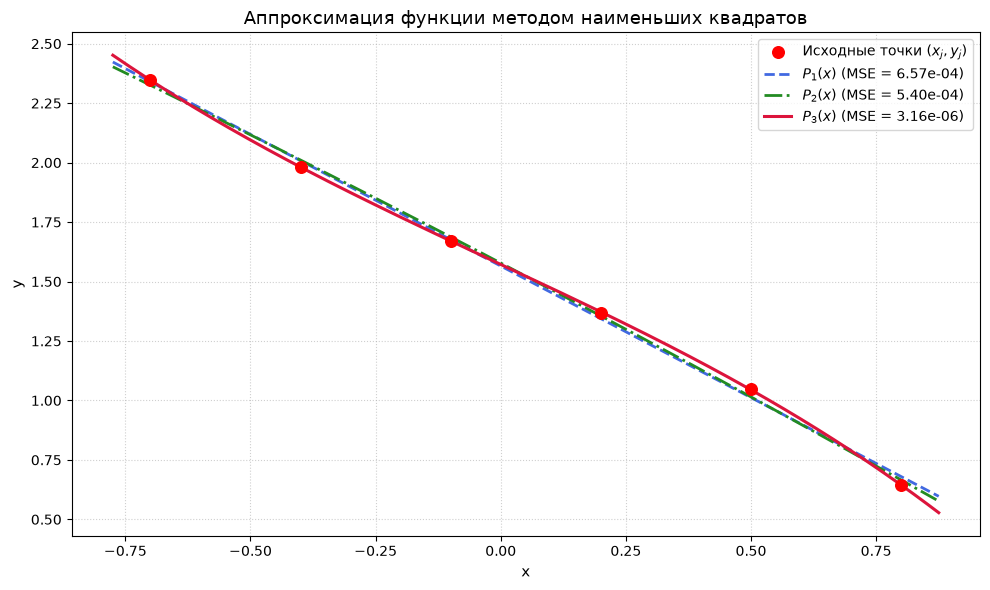

In [38]:
x_nodes_var9 = [-0.7, -0.4, -0.1, 0.2, 0.5, 0.8]
y_nodes_var9 = [2.3462, 1.9823, 1.6710, 1.3694, 1.0472, 0.64350]

solve_lsq_task(x_nodes_var9, y_nodes_var9)